# Football Player Rating: Data Cleaning, EDA and Modeling
 
**Goal.** Understand what drives a player's match rating (`player_rating`) and build a model that predicts it.
 
**Data.** 173,587 player-match records (63 raw columns) for 27,974 players in 6,818 matches across 188 league names, played between 31 Jan and 8 Jun 2025 (97 match dates). Each row is one player in one match.
 
**Structure.**
1. Data cleaning: missing values, outliers, duplicates and derived columns (output: `cleaned_data.csv`).
2. Exploratory data analysis (EDA).
3. Modeling: linear baseline vs HistGradientBoosting, grouped cross-validation, and predictions for the Power BI dashboard (output: `predictions.csv`).
 
**Dashboard.** The results are presented in a Power BI report (`football.pbix`).

# Uploading and Initial Review

In [3]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('football_player_rating_dataset.csv')
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 173587 entries, 0 to 173586
Data columns (total 63 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   match_id                  173587 non-null  int64  
 1   match_date                173587 non-null  str    
 2   league_id                 173587 non-null  int64  
 3   league_name               173587 non-null  str    
 4   country_code              173587 non-null  str    
 5   parent_league_name        173587 non-null  str    
 6   parent_league_season      173587 non-null  int64  
 7   home_team_id              173587 non-null  int64  
 8   home_team_name            173587 non-null  str    
 9   away_team_id              173587 non-null  int64  
 10  away_team_name            173587 non-null  str    
 11  home_score                173587 non-null  int64  
 12  away_score                173587 non-null  int64  
 13  is_home_team              173587 non-null  int64  
 14 

The raw dataset has 173,587 rows and 63 columns (match, league, team, player and in-match statistics). Each row is one player in one match. `match_date` is stored as text and is converted to a date in a later step.

In [5]:
df.head()

,match_id,match_date,league_id,league_name,country_code,parent_league_name,parent_league_season,home_team_id,home_team_name,away_team_id,...,duels_won,duels_lost,ground_duels_won,ground_duel_attempts,ground_duel_success_rate,aerial_duels_won,aerial_duel_attempts,aerial_duel_success_rate,fouls_committed,was_fouled
0,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,...,4.0,NaN,4.0,4.0,100.000000,0.0,0.0,NaN,0,1.0
1,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,...,3.0,2.0,3.0,5.0,60.000000,0.0,0.0,NaN,1,NaN
2,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,...,1.0,NaN,NaN,NaN,NaN,1.0,1.0,100.000000,0,NaN
3,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,...,4.0,5.0,3.0,7.0,42.900002,1.0,2.0,50.000000,1,1.0
4,4685005,2025-01-31,895986,Paulista A1,BRA,Paulista A1,2025,109705,Red Bull Bragantino,581838,...,4.0,3.0,3.0,4.0,75.000000,1.0,3.0,33.299999,0,NaN


In [6]:
df['match_date'] = pd.to_datetime(df['match_date'])

In [7]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
match_id,173587.0,7083235.476689,4196553.0,4534715.0,4692715.0,4727522.0,1000001005.0,49248750.384943
match_date,173587,2025-04-14 10:24:45.277123,2025-01-31 00:00:00,2025-03-26 00:00:00,2025-04-18 00:00:00,2025-05-07 00:00:00,2025-06-08 00:00:00,NaN
league_id,173587.0,746327.21989,47.0,208.0,893033.0,897032.0,10000002.0,1571396.92954
parent_league_season,173587.0,2025.0,2025.0,2025.0,2025.0,2025.0,2025.0,0.0
home_team_id,173587.0,223196.139302,1567.0,8239.0,9863.0,193025.0,1730349.0,416885.207011
away_team_id,173587.0,225465.840651,1567.0,8239.0,9860.0,191716.0,1730349.0,423353.690047
home_score,173587.0,1.554391,0.0,1.0,1.0,2.0,9.0,1.336574
away_score,173587.0,1.241988,0.0,0.0,1.0,2.0,10.0,1.199033
is_home_team,173587.0,0.494795,0.0,0.0,0.0,1.0,1.0,0.499974
team_goals,173334.0,1.379752,0.0,0.0,1.0,2.0,10.0,1.274929


Summary statistics show no negative or illogical values in `minutes_played` (10 to 120) or `player_rating` (2.43 to 9.97), so no correction is needed at this stage.

# Missing Values

In [8]:
missing_values = pd.DataFrame({
    'null_count': df.isna().sum(),
    'null_pct': (df.isna().mean() * 100).round(1)
})
missing_values = missing_values[missing_values.null_count > 0].sort_values('null_pct', ascending=False)
missing_values

,null_count,null_pct
expected_assists,109655,63.2
xg_plus_xa,103067,59.4
cross_success_rate,98270,56.6
cross_attempts,98270,56.6
accurate_crosses,98270,56.6
shots_on_target,92611,53.4
was_fouled,91436,52.7
dribble_attempts,90974,52.4
successful_dribbles,90974,52.4
dribble_success_rate,90974,52.4


No column is removed solely based on its percentage of null values; first, we determine the reason for the nulls.

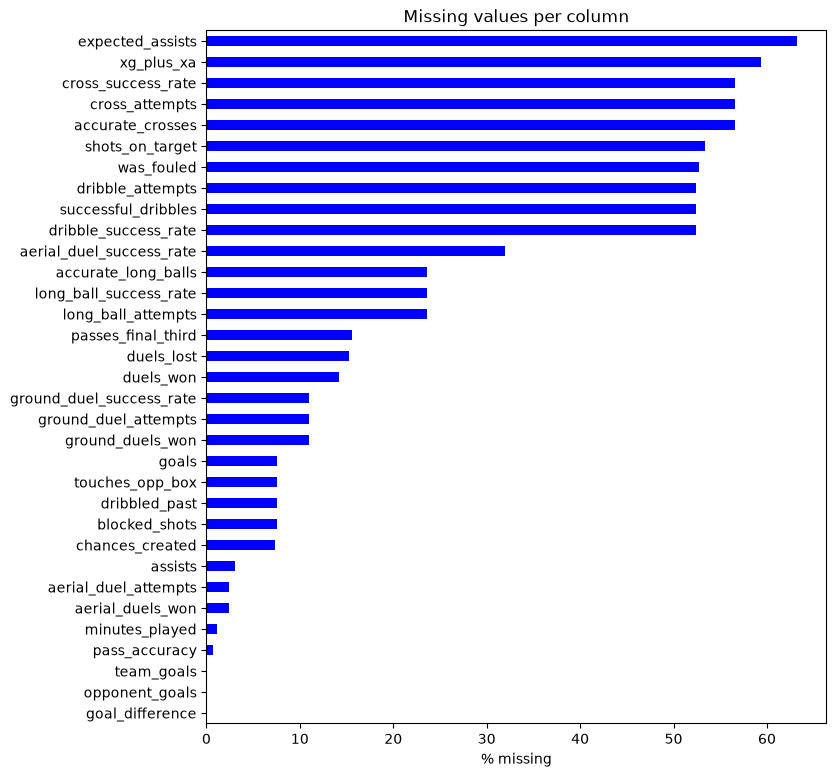

In [9]:
plt.figure(figsize=(8, 9))
missing_values.null_pct.plot.barh(color='blue')
plt.gca().invert_yaxis()
plt.xlabel('% missing')
plt.title('Missing values per column')
plt.show()

We will examine each group separately.

In [10]:
groups = {
    'dribble': ['successful_dribbles', 'dribble_attempts', 'dribble_success_rate'],
    'cross':   ['accurate_crosses', 'cross_attempts', 'cross_success_rate'],
    'longball':['accurate_long_balls', 'long_ball_attempts', 'long_ball_success_rate'],
}
for name, cols in groups.items():
    same = (df[cols].isna().nunique(axis=1) == 1).mean()
    print(name, 'same null rows:', round(same * 100, 1), '%')

dribble same null rows: 100.0 %
cross same null rows: 100.0 %
longball same null rows: 100.0 %


In all three groups, 100% of the rows share the same status. This means the `null` values ​​in these columns have a common cause: when a player has recorded zero instances of a dribble, cross, or long pass, none of the three associated metrics (successful, total, and percentage) have been recorded.
In these groups, this matter is interpreted as something that has not occurred.

In [11]:
xa = df.groupby('league_name')['expected_assists'].apply(lambda s: s.isna().mean())
print((xa == 1).sum(), 'of', len(xa), 'leagues have NO xA at all')

95 of 188 leagues have NO xA at all


A large portion of xA is "structural"—meaning that for those leagues, the data simply does not exist, rather than the value being equal to zero.

In [12]:
for c in ['dribble_attempts', 'cross_attempts', 'was_fouled', 'duels_won', 'passes_final_third', 'shots_on_target']:
    print(c, '| min =', df[c].min(), '| null % =', round(df[c].isna().mean() * 100, 1))

dribble_attempts | min = 1.0 | null % = 52.4
cross_attempts | min = 1.0 | null % = 56.6
was_fouled | min = 1.0 | null % = 52.7
duels_won | min = 1.0 | null % = 14.2
passes_final_third | min = 1.0 | null % = 15.6
shots_on_target | min = 0.0 | null % = 53.4


Five of these columns (`dribble_attempts`, `cross_attempts`, `was_fouled`, `duels_won`, `passes_final_third`) have a minimum of 1 and are never 0, which strongly suggests that a null means "performed zero times". `shots_on_target` is different: its minimum is 0, so zero is recorded explicitly. We therefore check, league by league, whether the metric is tracked at all (see the filling step below). Every league records `shots_on_target`, so its remaining nulls are treated as zero (an assumption: when a league tracks shots, a missing value means no shot on target).

In [13]:
goalkeepers = df.is_goalkeeper == 1
for c in ['goals', 'assists', 'blocked_shots', 'touches_opp_box', 'dribbled_past', 'chances_created']:
    n = df[c].isna()
    print(f'{c:18} null in GK: {(n & goalkeepers).sum():6}  null in outfield: {(n & ~goalkeepers).sum():6}')

goals              null in GK:  13128  null in outfield:      0
assists            null in GK:   5430  null in outfield:      0
blocked_shots      null in GK:  13131  null in outfield:      0
touches_opp_box    null in GK:  13142  null in outfield:      0
dribbled_past      null in GK:  13142  null in outfield:      0
chances_created    null in GK:  12624  null in outfield:      0


Across all these columns, `null` values ​​appear only for goalkeepers; not a single outfield player has a `null` value.
We fill it with zeros.

In [14]:
print('null pass_accuracy      :', df.pass_accuracy.isna().sum())
print('total_passes == 0       :', (df.total_passes == 0).sum())
print('both at the same time   :', (df.pass_accuracy.isna() & (df.total_passes == 0)).sum())

null pass_accuracy      : 1206
total_passes == 0       : 1206
both at the same time   : 1206


Every null in `pass_accuracy` corresponds exactly to a row with `total_passes = 0`. For percentage columns we recalculate the value from the numerator and denominator; when the denominator is zero the rate is undefined, so it is left as NaN (0% would wrongly mean "tried and failed every time").

In [15]:
tracked = df.groupby('league_name')['xg_plus_xa'].transform(lambda s: s.notna().any())
print('rows in leagues that track xG:', tracked.sum())
print('xg_plus_xa null share there  :', round(df[tracked].xg_plus_xa.isna().mean(), 3) * 100 , "%")
print('min xg_plus_xa :', df.xg_plus_xa.min())

rows in leagues that track xG: 112230
xg_plus_xa null share there  : 37.2 %
min xg_plus_xa : 0.0099999997764825


Even in leagues where the xG metric is recorded, 37.2% of the entries are null. The lowest value present is 0.01, and the number 0 does not appear; in other words, a value of zero is not explicitly recorded but instead manifests as "null."

In [16]:
valid_team = (df.team_id == df.home_team_id) | (df.team_id == df.away_team_id)
home_share = (df[valid_team].assign(h=(df.team_id == df.home_team_id).astype(int)).groupby('match_id')['h'].mean())
fix = ~valid_team
shares = df.loc[fix, 'match_id'].map(home_share)
assert shares.isin([0, 1]).all()
df.loc[fix, 'is_home_team'] = (1 - shares).astype(int)
df.loc[fix, 'team_id'] = np.where(df.loc[fix, 'is_home_team'] == 1, df.loc[fix, 'home_team_id'], df.loc[fix, 'away_team_id'])

id2name = (df[valid_team].drop_duplicates('team_id')
             .set_index('team_id')['team_name'])
new_names = df.loc[fix, 'team_id'].map(id2name)
print('fixed rows without a known name:', new_names.isna().sum())
df.loc[fix, 'team_name'] = new_names.fillna(df.loc[fix, 'team_name'])

chk = (df.loc[fix, ['match_id', 'home_team_name', 'away_team_name','team_id', 'team_name', 'is_home_team']].drop_duplicates('match_id'))
display(chk)

print('fixed rows:', fix.sum(), '| now home:', df.loc[fix, 'is_home_team'].sum())
print('still invalid:', (~((df.team_id == df.home_team_id) | (df.team_id == df.away_team_id))).sum())

fixed rows without a known name: 203


,match_id,home_team_name,away_team_name,team_id,team_name,is_home_team
4543,4548637,Sudtirol,AC Reggiana 1919,6500,Reggiana,0
11297,4548670,Catanzaro,AC Reggiana 1919,6500,Reggiana,0
17425,4548681,Cosenza,AC Reggiana 1919,6500,Reggiana,0
17510,4564086,Al-Fayha,Al Hilal,2529,Al-Hilal,0
35282,4548740,AC Reggiana 1919,Sampdoria,6500,Reggiana,1
38107,4730875,Inter Miami CF II,Miami United,634267,Miami United,0
38801,4730879,El Paso Locomotive FC,Harpos,1715265,Boulder Harpos,0
40934,4730890,Flatirons FC,Union Omaha,839086,Flatirons,1
42624,4756860,FC Rules the World,MVPs United,1730337,Rules The World,1
42652,4756862,NDL FC,Santan FC,1730343,Santan,0


fixed rows: 253 | now home: 109
still invalid: 0


In 253 rows (23 matches) `team_id` was not one of the two teams of the match. In these rows `team_name` was correct (only the spelling can differ from `home_team_name` / `away_team_name`, e.g. "Reggiana" vs "AC Reggiana 1919"), so the id was the faulty field. `is_home_team` and `team_id` were rebuilt by elimination: in each match all valid rows belong to one side, so the invalid rows belong to the opposite side. The 23 matches were checked one by one against the table above, and no invalid rows remain.

(The printed line "fixed rows without a known name: 203" only means that these team ids appear nowhere else in the data, so their original, correct names were kept.)

In [17]:
df['team_goals'] = np.where(df.is_home_team == 1, df.home_score, df.away_score)
df['opponent_goals'] = np.where(df.is_home_team == 1, df.away_score, df.home_score)
df['goal_difference'] = df.team_goals - df.opponent_goals
df['team_result'] = np.select([df.goal_difference > 0, df.goal_difference < 0], ['win', 'loss'], default='draw')
print(df.team_result.value_counts())
print(df[['team_goals', 'goal_difference']].isna().sum())

team_result
loss    66871
win     63733
draw    42983
Name: count, dtype: int64
team_goals         0
goal_difference    0
dtype: int64


Team goals, opponent goals, goal difference and the result are rebuilt from the final score and the corrected `is_home_team`: `team_goals` is `home_score` for home players and `away_score` otherwise, and `team_result` is win, draw or loss from the goal difference. No nulls remain in these columns.

In [18]:
df['minutes_missing'] = df['minutes_played'].isna().astype(int)
touch_bin = pd.qcut(df.touches, 10, duplicates='drop')
df['minutes_played'] = (df.groupby([touch_bin, 'is_goalkeeper'])['minutes_played'].transform(lambda s: s.fillna(s.median())))
print('still null:', df.minutes_played.isna().sum())

still null: 0


1,913 rows (1.1%) had unrecorded minutes.
These are players who have ratings and other statistics, so they must have played.
Deleting the rows would lose valid data in other columns, and filling with 0 would be incorrect (0 means "did not play"). The missing values are imputed with the median of players in the same touches decile and the same goalkeeper/outfield group, and `minutes_missing` marks the imputed rows.

In [19]:
df['has_xg_data'] = (df.groupby('league_id')['xg_plus_xa'].transform(lambda s: s.notna().any())).astype(int)

About 40% of the data (70,031 rows) belongs to leagues that do not record xG/xA at all. `has_xg_data` is 1 for leagues that record it and 0 otherwise, so the model can tell "not recorded" from "recorded as 0".

In [20]:
df["comp_format"] = np.where(
    df["league_name"].str.contains("Baller League", case=False, na=False),
    "6v6", "11v11")

women_keywords = "Women|Woman|Frauen|WSL|Liga F|Femenino|Feminino"
df["gender"] = np.where(
    df["league_name"].str.contains(women_keywords, case=False, na=False),
    "women", "men")

df["stage"] = "regular"
df.loc[df["league_name"].str.contains("Qualif|Qualifying", case=False, na=False), "stage"] = "qualification"
df.loc[df["league_name"].str.contains("Friendly", case=False, na=False), "stage"] = "friendly"
df.loc[df["league_name"].str.contains("Sidemen|Charity Match", case=False, na=False), "stage"] = "exhibition"
df.loc[df["league_name"].str.contains("Final Stage|Relegation|Playoff|Promotion|Play-In|Championship Group", case=False, na=False), "stage"] = "special"

print(df.groupby(["comp_format", "gender", "stage"])["player_rating"].agg(["count", "mean"]))

                                   count      mean
comp_format gender stage                          
11v11       men    exhibition         24  6.925000
                   qualification    3547  6.738151
                   regular        142670  6.777948
                   special         16643  6.802424
            women  regular          8381  6.708392
                   special           440  6.805273
6v6         men    regular          1818  6.907921
                   special            64  6.813750


Three descriptive columns are derived from `league_name` with keyword rules: `comp_format` (6v6 for "Baller League", otherwise 11v11), `gender` (women if the name contains Women, Frauen, WSL, Liga F, Femenino or Feminino) and `stage` (regular, qualification, special for finals, playoffs and relegation rounds, exhibition for charity or Sidemen matches). The rules are keyword-based and can misclassify unusual league names. Ratings differ little between the groups: about 6.91 for 6v6 vs 6.78 for 11v11, and 6.71 for women vs 6.78 for men in regular games.

In [21]:
count_cols = ['goals', 'assists', 'blocked_shots', 'chances_created', 'touches_opp_box',
              'successful_dribbles', 'dribble_attempts', 'passes_final_third',
              'accurate_crosses', 'cross_attempts', 'accurate_long_balls', 'long_ball_attempts',
              'dribbled_past', 'duels_won', 'duels_lost', 'ground_duels_won',
              'ground_duel_attempts', 'aerial_duels_won', 'aerial_duel_attempts', 'was_fouled']
df[count_cols] = df[count_cols].fillna(0)

for c in ['shots_on_target', 'expected_assists', 'xg_plus_xa']:
    tracked = df.groupby('league_id')[c].transform(lambda s: s.notna().any())
    df[c] = np.where(tracked, df[c].fillna(0), np.nan)
    print(f'{c:18} rows in untracked leagues: {(~tracked).sum():6} | NaN left: {df[c].isna().sum()}')

shots_on_target    rows in untracked leagues:      0 | NaN left: 0
expected_assists   rows in untracked leagues:  70031 | NaN left: 70031
xg_plus_xa         rows in untracked leagues:  70031 | NaN left: 70031


Filling rules:
- Goalkeepers: attacking statistics (goals, assists, blocked shots, ...) are not recorded for them, so their nulls become 0.
- Count columns whose minimum is 1 (dribbles, crosses, long balls, fouls suffered, duels, passes into the final third): a null means "did not happen", filled with 0.
- `shots_on_target`: recorded in every league, remaining nulls are filled with 0.
- `expected_assists` and `xg_plus_xa`: filled with 0 only in leagues that record them. In the 70,031 rows of leagues that do not record them they stay NaN, because "not recorded" is not the same as zero.
 
Why not the mean or median? For a player who made no crosses, a mean would silently give them a cross and distort the data.

In [22]:
def rate(a, b):
    return a / b.where(b > 0) * 100
 
df['dribble_success_rate']    = rate(df.successful_dribbles, df.dribble_attempts)
df['cross_success_rate']      = rate(df.accurate_crosses,    df.cross_attempts)
df['long_ball_success_rate']  = rate(df.accurate_long_balls, df.long_ball_attempts)
df['ground_duel_success_rate']= rate(df.ground_duels_won,    df.ground_duel_attempts)
df['aerial_duel_success_rate']= rate(df.aerial_duels_won,    df.aerial_duel_attempts)
df['pass_accuracy']           = rate(df.accurate_passes,     df.total_passes)

The percentage columns are recomputed from the count columns. Where the number of attempts is zero the rate is undefined and stays NaN (0% would mean the player tried and failed every time).

In [23]:
nulls = df.isna().sum()
print(nulls[nulls > 0])
print(df.shape)   # expected (173587, 68)

expected_assists            70031
xg_plus_xa                  70031
dribble_success_rate        90974
pass_accuracy                1206
cross_success_rate          98270
long_ball_success_rate      40887
ground_duel_success_rate    19153
aerial_duel_success_rate    55560
dtype: int64
(173587, 68)


After cleaning, nulls remain only in `expected_assists` and `xg_plus_xa` (leagues that do not record them) and in the rate columns where there were no attempts. They are left on purpose: tree-based models handle NaN natively, and the linear baseline imputes 0 inside its pipeline. The dataset now has 68 columns: 63 original + `minutes_missing`, `has_xg_data`, `comp_format`, `gender`, `stage`.

# Outliers

In [24]:
num_cols = [c for c in df.select_dtypes('number').columns if not c.endswith('_id')]
def iqr_outlier_pct(s):
 q1, q3 = s.quantile([.25, .75]); i = q3 - q1
 return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).mean() * 100
out = df[num_cols].apply(iqr_outlier_pct).sort_values(ascending=False)
print(out.head(15).round(1))

shots_on_target        21.5
accurate_crosses       18.9
aerial_duels_won       11.7
dribble_attempts       11.2
home_score              8.8
goals                   7.8
is_goalkeeper           7.6
clearances              7.5
expected_assists        7.4
accurate_long_balls     7.1
long_ball_attempts      7.1
fouls_committed         6.9
was_fouled              6.8
xg_plus_xa              5.9
assists                 5.6
dtype: float64


These percentages are misleading. In columns where most values are zero (such as `shots_on_target`), the third quartile is small; consequently the interquartile range (IQR) becomes approximately zero, and any non-zero value is classified as an "outlier". The IQR rule on its own is not a criterion for removing data. We must examine whether these values are truly impossible.

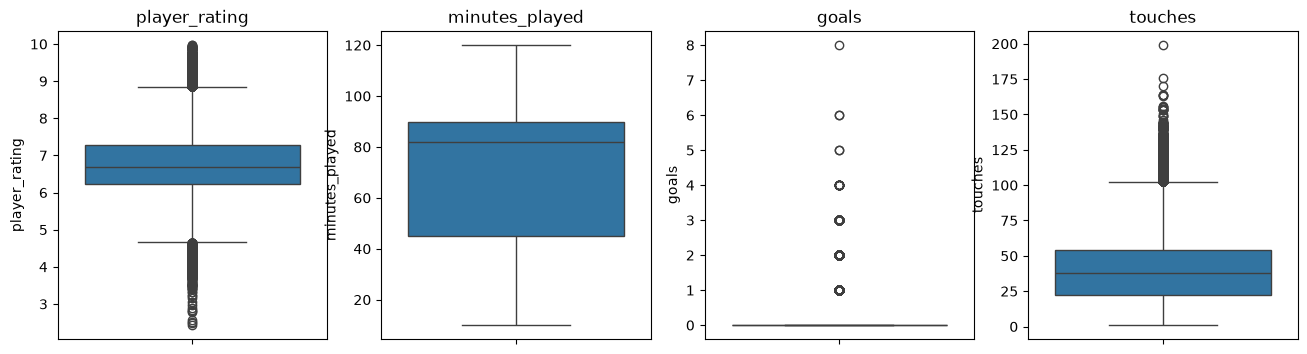

In [25]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, c in zip(ax, ['player_rating', 'minutes_played', 'goals', 'touches']):
 sns.boxplot(y=df[c], ax=a); a.set_title(c)
plt.show()

`minutes_played` contains no outliers (values between 10 and 120). `player_rating` has genuine extreme values at both ends of the scale. `goals` and `touches` have long right-skewed tails.
These values form a continuous distribution rather than isolated points, which indicates natural variation rather than data-entry errors.

In [26]:
print('minutes > 130 :', (df.minutes_played > 130).sum())
print('minutes < 1 :', (df.minutes_played < 1).sum())
print('rating outside 1-10 :', (~df.player_rating.between(1, 10)).sum())
print('pass_accuracy > 100 :', (df.pass_accuracy > 100).sum())
print('acc > total passes :', (df.accurate_passes > df.total_passes).sum())
print('succ > attempts drib :', (df.successful_dribbles > df.dribble_attempts).sum())
print('ground won > attempts:', (df.ground_duels_won > df.ground_duel_attempts).sum())
print('aerial won > attempts:', (df.aerial_duels_won > df.aerial_duel_attempts).sum())

minutes > 130 : 0
minutes < 1 : 0
rating outside 1-10 : 0
pass_accuracy > 100 : 0
acc > total passes : 0
succ > attempts drib : 0
ground won > attempts: 0
aerial won > attempts: 0


There are no impossible values. Therefore, all outliers are of the "very rare but possible" type.
No rows are removed or modified due to the presence of outliers, as these data points are real.

In [27]:
cols = ['player_name', 'team_name', 'minutes_played', 'goals', 'assists', 'player_rating']
print('Most goals in one match:')
display(df.sort_values('goals', ascending=False)[cols + ['is_goalkeeper', 'team_result']].head(5))
print('Lowest ratings:')
display(df.sort_values('player_rating')[cols + ['is_goalkeeper', 'team_result']].head(5))

Most goals in one match:


,player_name,team_name,minutes_played,goals,assists,player_rating,is_goalkeeper,team_result
143465,Kevin Weggen,Calcio Berlin,90.0,8.0,0.0,9.97,0,win
83346,Emre Yesilova,VFR Zimbos,67.0,6.0,0.0,9.96,0,draw
170589,Bilal Sayoud,26ers,87.0,6.0,1.0,9.97,0,loss
128364,Nils da Costa Perreira,Golden XI,78.0,5.0,0.0,9.96,0,win
158841,Marco Terrazzino,Gönrgy Allstars,78.0,5.0,0.0,9.95,0,win


Lowest ratings:


,player_name,team_name,minutes_played,goals,assists,player_rating,is_goalkeeper,team_result
78361,Mathieu Gorgelin,Le Havre,90.0,0.0,0.0,2.43,1,loss
142886,Paulo Vitor,Al-Akhdoud,47.0,0.0,0.0,2.49,1,loss
66581,Bleron Berisha,Hollywood United,90.0,0.0,0.0,2.51,1,loss
116710,Kewin Komar,Puszcza Niepolomice,90.0,0.0,0.0,2.58,1,loss
166689,Nicholas Hagen,Columbus Crew SC,90.0,0.0,0.0,2.79,1,loss


The five lowest ratings (2.43 to 2.79) all belong to goalkeepers whose teams lost, so a goalkeeper's rating depends heavily on goals conceded. At the other end, the five biggest goal tallies (5 to 8 goals in one match) all receive ratings of about 9.95 to 9.97, so the scale saturates near 10. Both groups are real extreme observations and are kept.

# Duplicate items and columns

In [28]:
print('full-row duplicates :', df.duplicated().sum())
print('match + player dups :', df.duplicated(subset=['match_id', 'player_id']).sum())
print('matches:', df.match_id.nunique(), '| players:', df.player_id.nunique())
df = df.drop_duplicates(subset=['match_id', 'player_id']).reset_index(drop=True)
print(df.shape)

full-row duplicates : 0
match + player dups : 0
matches: 6818 | players: 27974
(173587, 68)


There are no duplicates. We have 6,818 matches and 27,974 unique players.

In [29]:
const = [c for c in df.columns if df[c].nunique() == 1]
print('constant columns:', const)
print('parent_league_name == league_name:', (df.parent_league_name == df.league_name).mean())
df.select_dtypes(exclude='number').nunique()

constant columns: ['parent_league_season']
parent_league_name == league_name: 1.0


match_date               97
league_name             188
country_code             46
parent_league_name      188
home_team_name         1231
away_team_name         1233
team_result               3
player_name           27785
team_name              1354
comp_format               2
gender                    2
stage                     4
dtype: int64

`player_name` has 27,785 unique values while `player_id` has 27,974, and 472 names map to more than one id, so different players can share a name. Players must be grouped by `player_id`, never by name.
`parent_league_season` is constant (2025) and `parent_league_name` is identical to `league_name` (100% match), so both columns are redundant. They stay in the file for compatibility with the dashboard but are excluded from the model.

In [30]:
assert df.duplicated(['match_id', 'player_id']).sum() == 0
assert ((df.team_id == df.home_team_id) | (df.team_id == df.away_team_id)).all()
assert df.player_rating.between(1, 10).all()
assert df.shape == (173587, 68), df.shape
 
df.to_csv('cleaned_data.csv', index=False)
print('saved', df.shape)

saved (173587, 68)


Final integrity checks pass (no duplicate player-match rows, valid team ids, ratings within 1 to 10, expected shape). The cleaned dataset is saved as `cleaned_data.csv` (173,587 rows x 68 columns).

# Exploratory Data Analysis (EDA)

In [31]:
df = pd.read_csv('cleaned_data.csv')

In [32]:
print('league names with >1 league_id :', (df.groupby('league_name').league_id.nunique() > 1).sum())
print('team names with >1 team_id     :', (df.groupby('team_name').team_id.nunique() > 1).sum())
print('player names with >1 player_id :', (df.groupby('player_name').player_id.nunique() > 1).sum())

league names with >1 league_id : 12
team names with >1 team_id     : 10
player names with >1 player_id : 472


Names are not unique keys: 12 league names map to more than one league_id (e.g. Premier League, Serie A, Bundesliga across countries), 10 team names to more than one team_id, and 472 player names to more than one player_id. All joins and groupings must use league_id, team_id and player_id.

In [33]:
df['match_date'] = pd.to_datetime(df['match_date'])

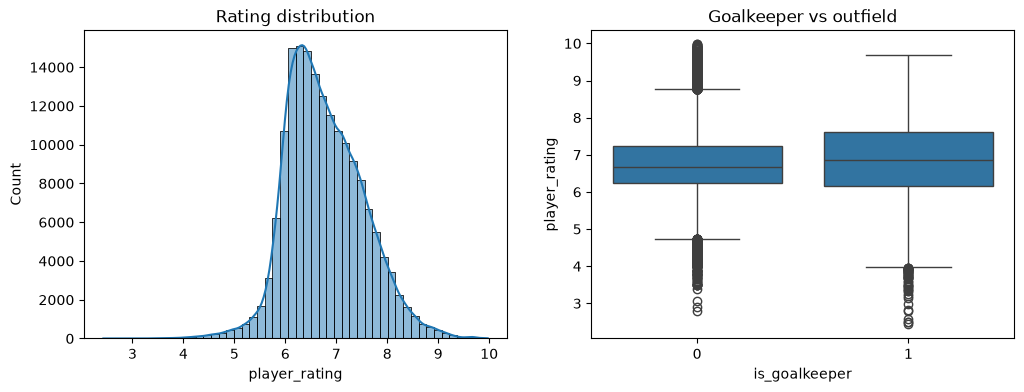

count    173587.00
mean          6.78
std           0.76
min           2.43
25%           6.23
50%           6.69
75%           7.28
max           9.97
Name: player_rating, dtype: float64
skew: 0.34
                count  mean  median   std
is_goalkeeper                            
0              160445  6.77    6.68  0.73
1               13142  6.85    6.87  1.02


In [34]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df.player_rating, bins=50, kde=True, ax=ax[0]); ax[0].set_title('Rating distribution')
sns.boxplot(data=df, x='is_goalkeeper', y='player_rating', ax=ax[1]); ax[1].set_title('Goalkeeper vs outfield')
plt.show()
print(df.player_rating.describe().round(2))
print('skew:', round(df.player_rating.skew(), 2))
print(df.groupby('is_goalkeeper').player_rating.agg(['count', 'mean', 'median', 'std']).round(2))

The distribution is approximately symmetric with a slight right skew (skewness 0.34). The overall mean is 6.78 and the standard deviation 0.76; most ratings fall between 6.2 and 7.3.
Goalkeepers and outfield players have similar means (6.85 vs 6.77), but goalkeepers' ratings are far more dispersed (standard deviation 1.02 vs 0.73).

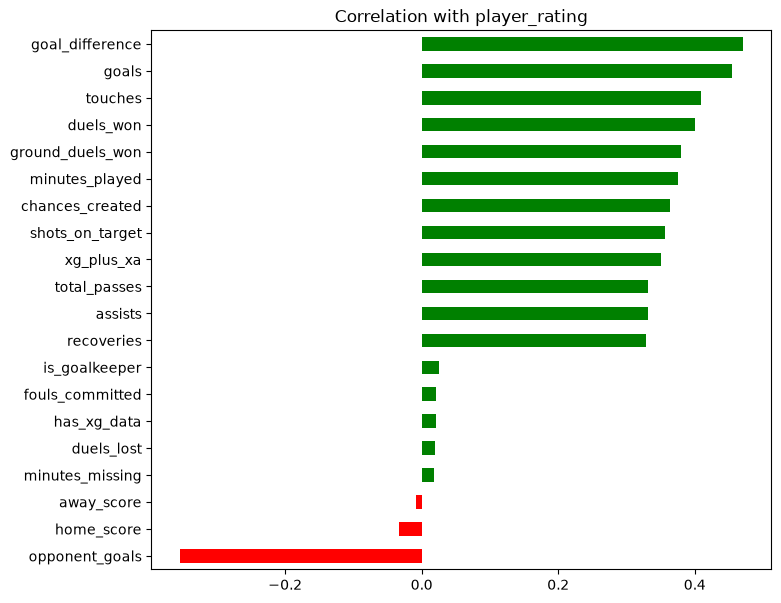

goal_difference     0.47
goals               0.45
touches             0.41
duels_won           0.40
ground_duels_won    0.38
minutes_played      0.38
chances_created     0.36
shots_on_target     0.36
xg_plus_xa          0.35
total_passes        0.33
Name: player_rating, dtype: float64


In [35]:
num_cols = [c for c in df.select_dtypes('number').columns if not c.endswith('_id')]
num_cols = [c for c in num_cols if df[c].nunique() > 1]
corr = df[num_cols].corr()['player_rating'].drop('player_rating').sort_values()
top = pd.concat([corr.head(8), corr.tail(12)])
top.plot.barh(figsize=(8, 7), color=np.where(top > 0, 'green', 'red'))
plt.title('Correlation with player_rating'); plt.show()
print(corr.sort_values(ascending=False).head(10).round(2))

None of the features exceed 0.5; this score cannot be explained by a single statistical indicator, but rather must be modeled using a combination of them.
The team's result is just as important as individual performance, and the more goals the opponent scores, the lower the rating becomes.

In [36]:
for gk, name in [(0, 'Outfield'), (1, 'Goalkeepers')]:
 sub = df[df.is_goalkeeper == gk]
 c = sub[num_cols].corr()['player_rating'].drop('player_rating')
 print(name, '- top 6 by |corr|')
 print(c.reindex(c.abs().sort_values(ascending=False).index).head(6).round(2), '\n')

Outfield - top 6 by |corr|
goals               0.49
goal_difference     0.46
duels_won           0.45
ground_duels_won    0.43
touches             0.43
minutes_played      0.41
Name: player_rating, dtype: float64 

Goalkeepers - top 6 by |corr|
opponent_goals             -0.72
goal_difference             0.57
ground_duel_success_rate    0.32
home_score                 -0.32
away_score                 -0.30
dribble_success_rate        0.24
Name: player_rating, dtype: float64 



For an outfield player, individual performance (goals, duels, touches) is the deciding factor.
For a goalkeeper, practically only goals conceded matter (-0.72). This is precisely why there is greater variance (dispersion) in goalkeeper ratings, and why predicting performance in this position is more difficult (as statistics regarding saves are not factored into the data).

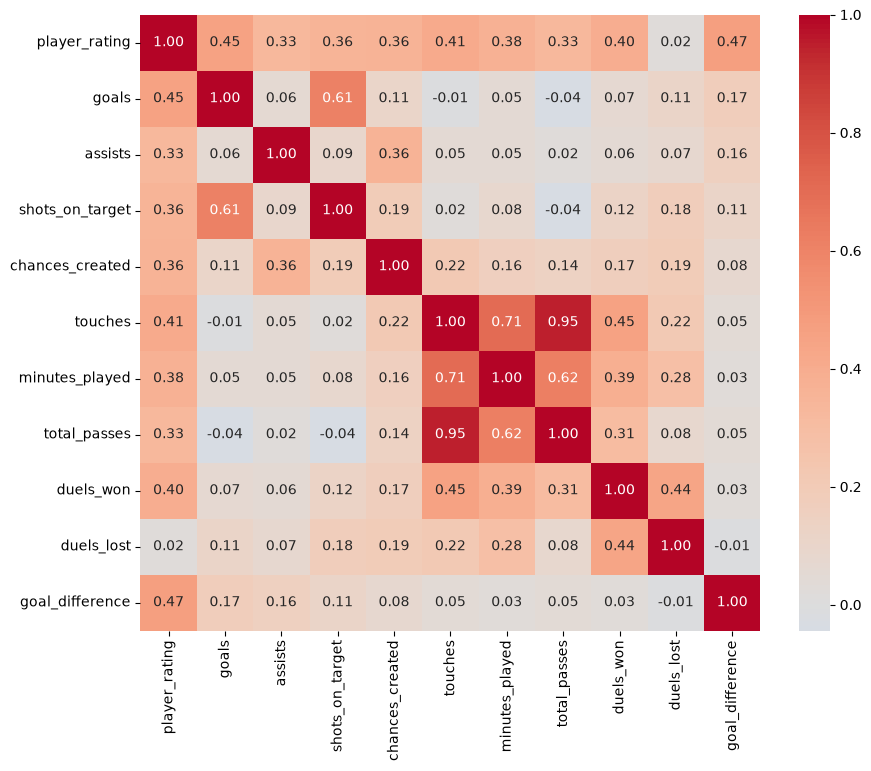

In [37]:
cols = ['player_rating', 'goals', 'assists', 'shots_on_target', 'chances_created', 'touches','minutes_played', 'total_passes', 'duels_won', 'duels_lost', 'goal_difference']
plt.figure(figsize=(10, 8))
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

The correlation between touches and total passes is 0.95 (they carry almost the same information); between touches and minutes played it is 0.71.
Goals and shots on target have a correlation of 0.61 (to score you have to shoot).
Duels won correlate with rating (0.40) while duels lost hardly do (0.02). A player who plays more wins more duels but also loses more, so the two effects probably cancel each other out.

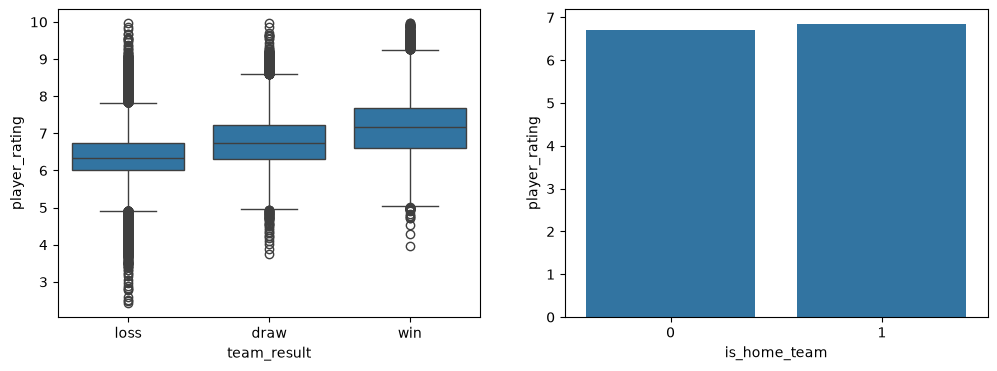

team_result
draw    6.80
loss    6.38
win     7.18
Name: player_rating, dtype: float64
is_home_team
0    6.71
1    6.85
Name: player_rating, dtype: float64
team_result    draw  loss   win
is_goalkeeper                  
0              6.79  6.40  7.16
1              7.00  6.11  7.45


In [38]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='team_result', y='player_rating', order=['loss', 'draw', 'win'], ax=ax[0])
sns.barplot(data=df, x='is_home_team', y='player_rating', ax=ax[1])
plt.show()
print(df.groupby('team_result').player_rating.mean().round(2))
print(df.groupby('is_home_team').player_rating.mean().round(2))
print(df.groupby(['is_goalkeeper', 'team_result']).player_rating.mean().round(2).unstack())

Ratings rise with the team result: Loss < Draw < Win (win minus loss ≈ 0.8). This is expected, and the boxes overlap, so the result shifts the rating but does not determine it.

The team result moves a goalkeeper's rating by about 1.33 (win vs loss), roughly 1.75 times the effect on an outfield player (≈ 0.76). The goalkeeper of the winning team gets the best rating (7.45), while the goalkeeper of the losing team gets the worst (6.11). Note that the dataset only distinguishes goalkeepers from outfield players, not individual positions.

The difference between home and away players is only 0.14.

In [39]:
print(pd.crosstab(df.is_home_team, df.team_result, normalize='index').round(3))
print(df.groupby(['team_result', 'is_home_team']).player_rating.mean().round(2).unstack())

team_result    draw   loss    win
is_home_team                     
0             0.247  0.457  0.296
1             0.248  0.312  0.439
is_home_team     0     1
team_result             
draw          6.80  6.81
loss          6.36  6.40
win           7.17  7.19


Home teams win far more often (43.9% vs 29.6%). But when the outcome is held constant, the ratings of home and away players are almost the same (6.80 vs 6.81 in a draw, 6.36 vs 6.40 in a loss, 7.17 vs 7.19 in a win).
So most of the 0.14 gap comes from confounding: home teams win more, and winners get higher ratings. Playing at home has at most a very small direct effect (0.01 to 0.04). `is_home_team` stays as a feature, but we should not expect much from it and should not claim that playing at home raises a rating.

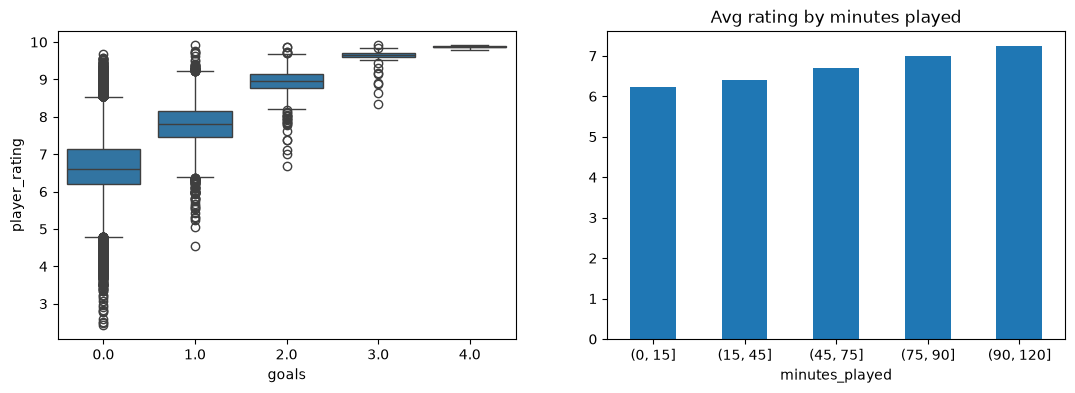

        count  mean
goals              
0.0    160053  6.68
1.0     12348  7.81
2.0      1062  8.94
3.0       105  9.61
4.0        19  9.90


In [40]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df[df.goals <= 4], x='goals', y='player_rating', ax=ax[0])
bins = pd.cut(df.minutes_played, [0, 15, 45, 75, 90, 120])
df.groupby(bins).player_rating.mean().plot.bar(ax=ax[1], rot=0)
ax[1].set_title('Avg rating by minutes played'); plt.show()
print(df.groupby(df.goals.clip(upper=4)).player_rating.agg(['count', 'mean']).round(2))

Rating by goals: each of the first two goals adds about 1.13 points (almost linear); the third adds 0.67 and the fourth only 0.28, because ratings saturate near the maximum of 10.
Rating by minutes played: the average rises from 6.24 for players with up to 15 minutes to 7.25 for those who played more than 90 minutes. Part of this is genuine (more time to influence the game) and part is selection (better players play longer).

70 leagues with n>=500


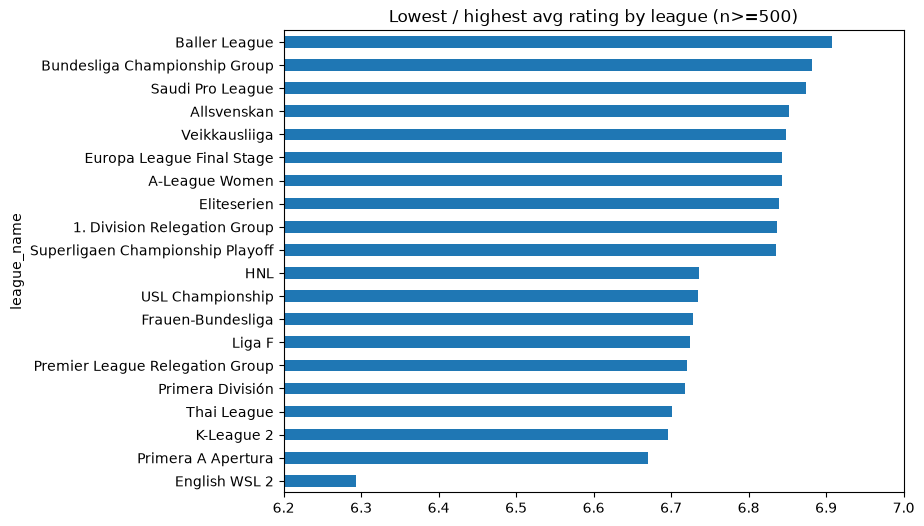

In [41]:
lg = df.groupby('league_name').agg(n=('player_rating', 'size'), avg_rating=('player_rating', 'mean'), goals=('goals', 'sum'))
lg = lg[lg.n >= 500].sort_values('avg_rating')
print(len(lg), 'leagues with n>=500')
pd.concat([lg.head(10), lg.tail(10)])['avg_rating'].plot.barh(figsize=(8, 6))
plt.xlim(6.2, 7.0)
plt.title('Lowest / highest avg rating by league (n>=500)')
plt.show()

The leagues are very similar: 80% of the league averages (leagues with at least 500 rows) lie between 6.73 and 6.84, and the standard deviation of the averages is only 0.07. League alone is therefore a weak predictor of a rating.

In [42]:
pl = df.groupby('player_id').agg(player_name=('player_name', 'first'),
        matches=('match_id', 'nunique'), avg_rating=('player_rating', 'mean'),
        goals=('goals', 'sum'), assists=('assists', 'sum')).reset_index()

display(pl[pl.matches >= 10].sort_values('avg_rating', ascending=False).head(15))
print('players with >=10 matches:', (pl.matches >= 10).sum(), 'of', len(pl))

,player_id,player_name,matches,avg_rating,goals,assists
10221,835903,Mariona Caldentey,10,8.311000,7.0,1.0
13370,979376,Emam Ashour,10,8.100000,5.0,3.0
2684,307753,Salem Al-Dawsari,12,8.088333,7.0,6.0
6420,623547,Cristian Guanca,12,8.065000,8.0,5.0
14040,1031791,Claudia Pina,13,8.062308,13.0,5.0
7683,684725,Lucas Fernandes,11,8.039091,3.0,8.0
14266,1044167,Alexandra Chidiac,11,8.031818,1.0,3.0
6236,617308,Mourad Batna,10,8.009000,5.0,5.0
3085,358289,Carles Gil,10,8.007000,4.0,2.0
2590,303339,Sadio Mané,12,7.990000,9.0,5.0


players with >=10 matches: 6026 of 27974


Among players with at least 10 matches, the highest average ratings belong to well-known stars (for example Claudia Pina, Lionel Messi, Sadio Mané and Lamine Yamal), a useful sanity check that the rating reflects real quality.
Only about 21% of players (6,026 of 27,974) have at least 10 matches; most players have few matches, so their averages are unstable.

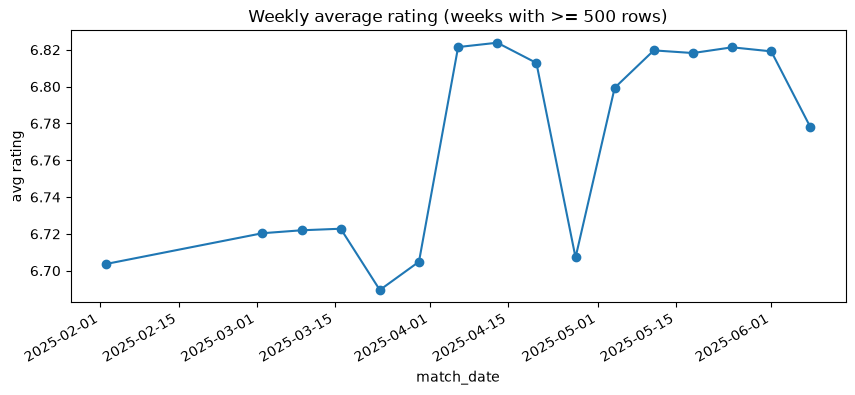

In [43]:
weekly = df.set_index('match_date')['player_rating'].resample('W').agg(['mean', 'count'])
weekly = weekly[weekly['count'] >= 500]
weekly['mean'].plot(figsize=(10, 4), marker='o')
plt.title('Weekly average rating (weeks with >= 500 rows)')
plt.ylabel('avg rating')
plt.show()

Coverage over time is uneven. The first week (to Feb 2) has 5,617 rows, the week to Feb 9 only 464, and there is no data for the two weeks ending Feb 16 and Feb 23. From March the volume is roughly 5k–12k rows per week and peaks around 15k–16k in April–May. The weekly mean is about 6.7 until March and about 6.82 from April on, which coincides with the volume increase. The rise may therefore reflect which leagues are covered in each period rather than a real change in ratings.

In [44]:
for col in ["comp_format", "gender", "stage"]:
    print(f"=== {col} ===")
    print(df.groupby(col)["player_rating"].agg(["count", "mean", "std"]).round(3), "\n")

=== comp_format ===
              count   mean    std
comp_format                      
11v11        171705  6.776  0.751
6v6            1882  6.905  1.198 

=== gender ===
         count   mean    std
gender                      
men     164766  6.781  0.754
women     8821  6.713  0.817 

=== stage ===
                count   mean    std
stage                              
exhibition         24  6.925  1.461
qualification    3547  6.738  0.731
regular        152869  6.776  0.756
special         17147  6.803  0.779 



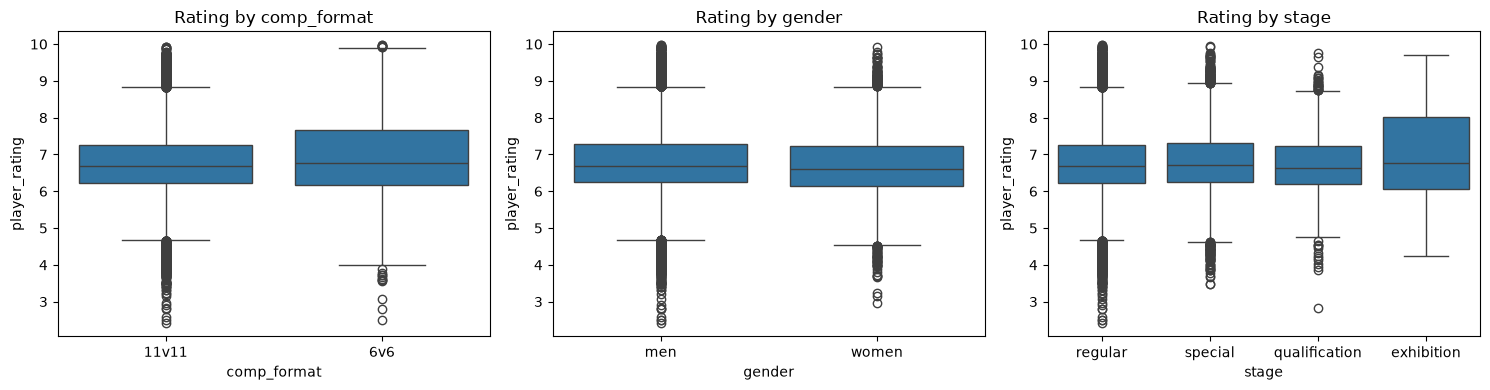

In [45]:
import seaborn as sns
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["comp_format", "gender", "stage"]):
    sns.boxplot(data=df, x=col, y="player_rating", ax=a)
    a.set_title(f"Rating by {col}")
plt.tight_layout(); plt.show()

Rating differences across `comp_format`, `gender` and `stage` are small relative to the overall standard deviation (0.76): about 6.91 for 6v6 vs 6.78 for 11v11, and 6.71 for women vs 6.78 for men. The 6v6 group has only 1,882 rows and a much larger spread (standard deviation 1.20 vs 0.75), so conclusions about it are less reliable. The `exhibition` stage has only 24 rows and should not be interpreted.

# Model Preparation, Training, and Evaluation

**Goal.** Predict `player_rating` from a player's match statistics.
 
**Two feature sets.** A uses individual statistics only. B adds `team_goals` and `opponent_goals`. The EDA showed that goals conceded is the strongest signal for goalkeepers (correlation -0.72) and that the team result shifts the ratings of all players, so B measures how much the match context adds. A measures individual performance alone; B explains a rating given the match outcome.
 
**Split.** 80/20, grouped by `match_id`, so no match appears in both sets.
 
**Models.** Linear regression (baseline) and HistGradientBoosting, with hyperparameters tuned by grouped 3-fold cross-validation on the training data only.

In [46]:
import time
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
 
df = pd.read_csv('cleaned_data.csv')
df['match_date'] = pd.to_datetime(df['match_date'])

In [47]:
df['total_duels']      = df.duels_won + df.duels_lost
df['shot_involvement'] = df.shots_on_target + df.blocked_shots   # NaN in leagues that do not track it
df['goal_contrib']     = df.goals + df.assists
df['pass_per_min']     = df.total_passes / df.minutes_played
df['touches_per_min']  = df.touches / df.minutes_played
 
cat_cols = ['league_name', 'comp_format', 'gender', 'stage', 'is_goalkeeper', 'is_home_team']
context_cols = ['team_goals', 'opponent_goals']
base_drop = ['match_id', 'match_date', 'league_id', 'country_code', 'parent_league_name',
             'parent_league_season', 'home_team_id', 'home_team_name', 'away_team_id',
             'away_team_name', 'player_id', 'player_name', 'team_id', 'team_name',
             'home_score', 'away_score', 'team_result', 'goal_difference'] + context_cols
 
def build_X(use_context):
    drop = base_drop if not use_context else [c for c in base_drop if c not in context_cols]
    X = df.drop(columns=drop + ['player_rating'])
    return pd.get_dummies(X, columns=cat_cols, drop_first=True)
 
X_A = build_X(False)   # individual stats only
X_B = build_X(True)    # + team_goals and opponent_goals
y = df['player_rating']
 
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(df, groups=df.match_id))
print(X_A.shape, X_B.shape, '| train/test:', len(train_idx), len(test_idx))
print('shared matches:', len(set(df.match_id.iloc[train_idx]) & set(df.match_id.iloc[test_idx])))

(173587, 240) (173587, 242) | train/test: 138933 34654
shared matches: 0


Feature engineering adds `total_duels`, `shot_involvement`, `goal_contrib`, `pass_per_min` and `touches_per_min`. Identifier, name, score and result columns are removed and categorical columns are one-hot encoded (240 features for A, 242 for B). The split is by match: 138,933 training rows, 34,654 test rows and no shared matches.

In [48]:
def evaluate(X, label):
    Xtr, Xte = X.iloc[train_idx], X.iloc[test_idx]
    ytr, yte = y.iloc[train_idx], y.iloc[test_idx]
    models = {
      'Linear': make_pipeline(SimpleImputer(strategy='constant', fill_value=0),
                              StandardScaler(), LinearRegression()),
      'HGB': HistGradientBoostingRegressor(max_iter=1000, learning_rate=0.05,
                 early_stopping=True, validation_fraction=0.1,
                 n_iter_no_change=30, random_state=42)}
    rows, fitted = [], {}
    for name, m in models.items():
        t = time.time(); m.fit(Xtr, ytr); fitted[name] = m
        for split, Xs, ys in [('train', Xtr, ytr), ('test', Xte, yte)]:
            p = m.predict(Xs)
            rows.append([label, name, split, mean_absolute_error(ys, p),
                         mean_squared_error(ys, p) ** 0.5, r2_score(ys, p)])
        print(label, name, 'done', round(time.time() - t), 's')
    return pd.DataFrame(rows, columns=['features','model','split','MAE','RMSE','R2']).round(3), fitted
 
res_A, fit_A = evaluate(X_A, 'A individual')
res_B, fit_B = evaluate(X_B, 'B + team goals')
pd.concat([res_A, res_B])

A individual Linear done 7 s
A individual HGB done 22 s
B + team goals Linear done 5 s
B + team goals HGB done 38 s


,features,model,split,MAE,RMSE,R2
0,A individual,Linear,train,0.291,0.442,0.660
1,A individual,Linear,test,0.293,0.443,0.658
2,A individual,HGB,train,0.261,0.401,0.720
3,A individual,HGB,test,0.278,0.429,0.679
0,B + team goals,Linear,train,0.246,0.361,0.773
1,B + team goals,Linear,test,0.248,0.362,0.772
2,B + team goals,HGB,train,0.138,0.223,0.914
3,B + team goals,HGB,test,0.153,0.251,0.890


With individual statistics only (A), boosting beats the linear baseline (test R² 0.679 vs 0.658, MAE 0.278 vs 0.293). Adding team goals (B) lifts the boosting model to R² 0.890 (MAE 0.153) and the linear model to R² 0.772. The linear models show almost no train/test gap; the boosting model on B has a small gap (R² 0.914 vs 0.890), so overfitting is mild.

In [49]:
gk_test = (df.is_goalkeeper.iloc[test_idx] == 1).values
yte = y.iloc[test_idx].values
for label, X, fit in [('A', X_A, fit_A), ('B', X_B, fit_B)]:
    p = fit['HGB'].predict(X.iloc[test_idx])
    for nm, mk in [('Goalkeepers', gk_test), ('Outfield', ~gk_test)]:
        print(label, nm, 'MAE', round(mean_absolute_error(yte[mk], p[mk]), 3),
              'R2', round(r2_score(yte[mk], p[mk]), 3), 'n =', mk.sum())

A Goalkeepers MAE 0.747 R2 0.17 n = 2633
A Outfield MAE 0.24 R2 0.759 n = 32021
B Goalkeepers MAE 0.386 R2 0.748 n = 2633
B Outfield MAE 0.134 R2 0.913 n = 32021


The weakness of A is concentrated in goalkeepers: R² 0.17 (MAE 0.747) vs 0.759 for outfield players. With B the goalkeeper R² rises to 0.748 (MAE 0.386) and the outfield R² to 0.913 (MAE 0.134). This confirms the EDA finding that a goalkeeper's rating is driven by goals conceded, which A cannot see.
Decision: B is used as the final model. It explains a rating given the match context; it is not a pre-match forecast. Note that this choice was made after looking at test-set scores.

In [50]:
X_final = X_B
 
Xtr, ytr = X_final.iloc[train_idx], y.iloc[train_idx]
groups = df.match_id.iloc[train_idx].values
rows = []
for lr_, leaf, l2 in itertools.product([0.05, 0.1], [31, 63], [0.0, 1.0]):
    m = HistGradientBoostingRegressor(max_iter=1000, learning_rate=lr_, max_leaf_nodes=leaf,
            l2_regularization=l2, early_stopping=True, n_iter_no_change=30, random_state=42)
    s = cross_val_score(m, Xtr, ytr, groups=groups, cv=GroupKFold(3), scoring='r2', n_jobs=-1)
    rows.append((lr_, leaf, l2, round(s.mean(), 4), round(s.std(), 4)))
cv = pd.DataFrame(rows, columns=['learning_rate','max_leaf_nodes','l2','cv_r2','cv_std'])
cv = cv.sort_values('cv_r2', ascending=False)
cv

,learning_rate,max_leaf_nodes,l2,cv_r2,cv_std
1,0.05,31,1.0,0.8844,0.0032
2,0.05,63,0.0,0.8843,0.0027
3,0.05,63,1.0,0.8843,0.0029
0,0.05,31,0.0,0.8840,0.0033
4,0.10,31,0.0,0.8832,0.0029
7,0.10,63,1.0,0.8830,0.0029
5,0.10,31,1.0,0.8829,0.0029
6,0.10,63,0.0,0.8827,0.0027


Hyperparameters were tuned with 3-fold cross-validation grouped by match, on the training data only. All eight combinations score between 0.8827 and 0.8844 (R²), so the model is insensitive to these settings. The best one (learning rate 0.05, 31 leaves, L2 = 1.0) is used for the final model.

TEST MAE 0.154 | RMSE 0.251 | R2 0.89 | iterations: 1000


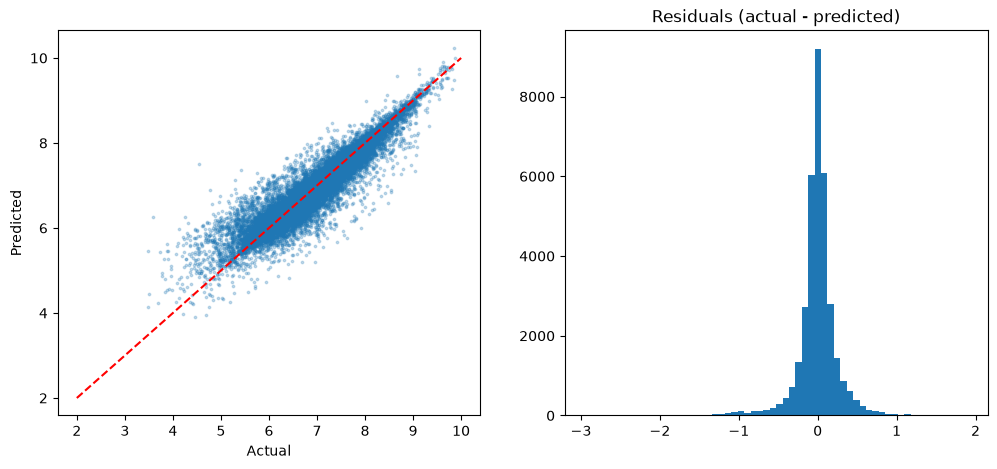

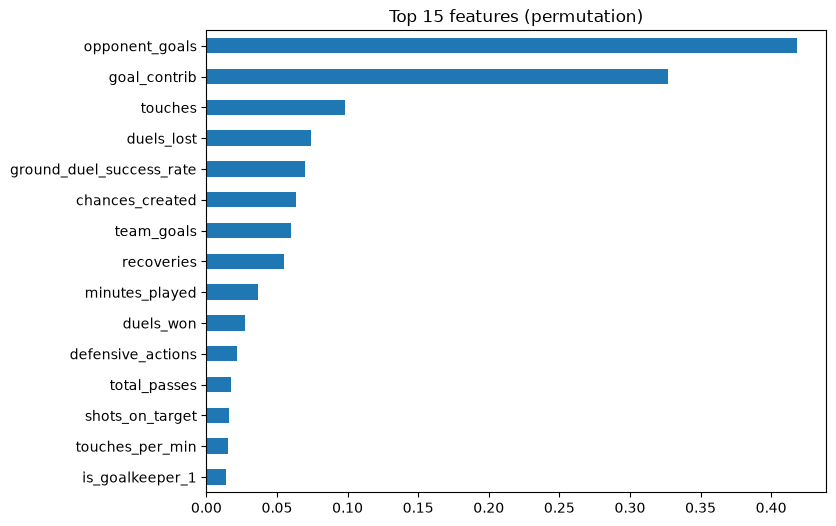

In [52]:
best = cv.iloc[0]

final = HistGradientBoostingRegressor(max_iter=1000, learning_rate=float(best.learning_rate), max_leaf_nodes=int(best.max_leaf_nodes),
                                       l2_regularization=float(best.l2), early_stopping=True, n_iter_no_change=30, random_state=42)

final.fit(Xtr, ytr)

Xte = X_final.iloc[test_idx]
yte_s = y.iloc[test_idx]

pred = final.predict(Xte)

print('TEST MAE', round(mean_absolute_error(yte_s, pred), 3),
      '| RMSE', round(mean_squared_error(yte_s, pred) ** 0.5, 3),
      '| R2', round(r2_score(yte_s, pred), 3),
      '| iterations:', final.n_iter_)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter( yte_s, pred, s=3, alpha=.25)
ax[0].plot([2, 10], [2, 10], 'r--')

ax[0].set_xlabel('Actual')
ax[0].set_ylabel('Predicted')
ax[1].hist( yte_s - pred, bins=60)
ax[1].set_title('Residuals (actual - predicted)')

plt.show()

sample = Xte.sample(min(5000, len(Xte)), random_state=1)

r = permutation_importance(
    final,
    sample,
    y.loc[sample.index],
    n_repeats=5,
    random_state=0,
    n_jobs=-1)

imp = pd.Series(r.importances_mean,index=X_final.columns).sort_values( ascending=False).head(15)
imp.sort_values().plot.barh(figsize=(8, 6))
plt.title('Top 15 features (permutation)')

plt.show()

Final model on the held-out test set: MAE 0.154, RMSE 0.251, R² 0.89. Predictions follow the diagonal and the residuals are centred on zero; the model is least accurate at the extremes, where very low ratings tend to be over-predicted. The final model used all 1,000 allowed iterations, so early stopping did not trigger and more iterations might improve it slightly.
Permutation importance (5,000-row sample) is dominated by `opponent_goals` (about 0.42) and `goal_contrib` (about 0.33), followed by `touches`, `duels_lost`, `ground_duel_success_rate`, `chances_created`, `team_goals` and `recoveries`. Correlated features share importance, so individual rankings should be interpreted with caution.

In [53]:
pred_df = df.iloc[test_idx][['match_id', 'match_date', 'league_id', 'league_name',
                             'team_id', 'team_name', 'player_id', 'player_name',
                             'player_rating', 'is_goalkeeper', 'comp_format', 'gender',
                             'stage', 'team_result', 'minutes_played']].copy()
pred_df['predicted_rating'] = pred.round(3)
pred_df['error']     = (pred_df.player_rating - pred_df.predicted_rating).round(3)
pred_df['abs_error'] = pred_df.error.abs()
pred_df['player_rating']  = pred_df.player_rating.round(2)
pred_df['minutes_played'] = pred_df.minutes_played.round(0).astype(int)
 
assert pred_df.shape[1] == 18, pred_df.shape
pred_df.to_csv('predictions.csv', index=False)
joblib.dump({'model': final, 'columns': list(X_final.columns)}, 'rating_model.joblib')
print(pred_df.shape, pred_df.columns.tolist())

(34654, 18) ['match_id', 'match_date', 'league_id', 'league_name', 'team_id', 'team_name', 'player_id', 'player_name', 'player_rating', 'is_goalkeeper', 'comp_format', 'gender', 'stage', 'team_result', 'minutes_played', 'predicted_rating', 'error', 'abs_error']


`predictions.csv` (34,654 test rows, 18 columns including `league_id` and `team_id`) feeds the Model page of the Power BI report (actual vs predicted, error by league, gender, format and role). The trained model and its feature list are saved in `rating_model.joblib`.

## Conclusions
 
1. Ratings are driven by a player's involvement (goals, touches, duels) and strongly by the match outcome: compared with a loss, a win adds about 0.8 points for outfield players and about 1.3 for goalkeepers.
2. With individual statistics only, the best model explains about 68% of the variance (R² 0.679, MAE 0.28). Goalkeepers are the weak point (R² 0.17) because saves are not in the data and goals conceded is hidden from this feature set.
3. Adding team goals scored and conceded raises R² to 0.89 (MAE 0.15; goalkeepers R² 0.75). This model explains a rating given the match context; it cannot forecast a rating before the match.
4. League, gender, competition format and stage have little effect on the rating. 6v6 matches are more dispersed and few.
5. Playing at home changes the result more than it changes the rating.
 
**Limitations.** The data covers about four months with uneven weekly coverage; 40% of the rows come from leagues that do not record xG/xA; the split is random by match, not chronological; the final model used all 1,000 iterations; and the choice between feature sets A and B was made after looking at test-set scores.